In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numba import jit

In [2]:
@jit
def hazards(y,c_idx,num_reax,N,y_tot,beta,gamma,sigma):
    a =np.zeros(num_reax)                                     #reaction hazards 
    v=np.zeros([num_reax,max_size])                           #reaction vectors

    a[0]=(k_tr*y_tot)/(1+K*y_tot/(s0*n))**n
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1

    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -2
                else:
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                v[i,int(np.sum(species_idx[:,i]))] = 1
            else:                            #plasmid shedding         
                v[i,0] = 1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])-1] = 1   
    return a,v
    
@jit    
def ssa_hyperbolic(y0,x0,tau,beta,gamma,sigma):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i 
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot=x0#y[0]
    for i in np.arange(2,len(y)):
        y_tot+=i*y[i]
    while t_y<tau:
        c_idx = np.where(y>0)[0]                                  #indices of species with non-zero state
        N= len(c_idx)
        num_reax = N+1+int(((N-1)**2-N+1)/2)+2*(N-1)              #possible number of reactions given the system state 
        a,v = hazards(y,c_idx,num_reax,N,y_tot,beta,gamma,sigma)
        
        sum_a=np.sum(a)
        cumsum_a=np.cumsum(a,axis=0)
        epsilon=np.random.uniform(0,1,2)
        j=np.min(np.where(epsilon[0]*sum_a<cumsum_a)) 
        t_f=(np.log(1/epsilon[1]))/sum_a
          
        if t_y+t_f<=tau:  
            t_y+=t_f 
            y+=v[j,:]
            y[0]+=y[1]
            y[1]=0
            y_tot =y[0]
            for i in np.arange(1,max_size):
                y_tot +=i*y[i] 
            if j==0:
                x= np.append(x,y_tot)
                t_x =np.append(t_x,[t_y])
        else:
            t_y=tau
            x=np.append(x,x[-1])
            t_x =np.append(t_x,[t_y])        
    return y,x,t_y,t_x

@jit
def single_lineage(x0,gen,tau,cluster,thresh,beta,gamma,sigma):
    x=[x0]
    t=[0]
    y0 = np.zeros(max_size)
    y0[0]=x0
    cluster_num = np.zeros(gen)
    ratio = np.zeros([gen,2])  #ratio = [inheritance,parent]
    z=np.zeros(max_size)   #keep track of n-cluster numbers
    count=0
    for i in range(gen):
        if x0>0:
            count+=1
            yy,xx,tty,ttx=ssa_hyperbolic(y0,x0,tau,beta,gamma,sigma)
            if cluster==False:
                x0=np.random.binomial(xx[-1],0.5)
            else:
                x=np.append(x,xx)
                t=np.append(t,t[-1]+ttx)
                clusters = yy[:np.max(np.where(yy>0))+1]
                clusters[1] = clusters[0]
                x0=0
                ################  just for finding cluster distribution #####################
                while x0==0:
                    y0=np.zeros(len(yy))
                    for k in np.arange(1,len(clusters)):    #cluster segregation; binomial
                        seg_count = np.random.binomial(int(clusters[k]),0.5)
                        y0[k]=seg_count 
                        x0+=k*seg_count
                    y0[0]=y0[1]
                    y0[1]=0
            ratio[i,:]=[xx[-1],x0/xx[-1]]
            z+=yy
        cluster_num[i] = np.sum(yy[thresh:]) 

    return x,t,ratio[:count,:],cluster_num[:count],z


def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[0].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[0].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[0].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[0].set_ylim([0,max(x)+1])
    axes[0].set_xlim([0,gen*tau])
    axes[0].set_xlabel('Time (min)')
    axes[0].set_ylabel('Plasmid copy number')
    return None

def plot_stairs_multiple(x,t,k):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[k].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[k].set_ylim([0,100])
    axes[k].set_xlim([0,gen*tau])
    axes[k].set_xlabel('time')
    axes[k].hlines(41,0,gen*tau,color='grey')
    if k>0:
        axes[k].set_yticklabels([])
    return None

In [3]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=200
beta = 0.1 #plasmid recruitment rate constant
gamma = 0.5*beta #plasmid combination rate constant
sigma= 0.5*beta  #plasmid dissociation rate constant

#for testing

gen=1
y0 = np.zeros(max_size)
y0[0]=x0
f,axes = plt.subplots(2,1,figsize=(4,5))
y,x,t_y,t_x = ssa_hyperbolic(y0,x0,tau)
plot_stairs(x,t_x)
axes[1].bar(range(np.max(np.where(y>0))+1),y[:np.max(np.where(y>0))+1])
axes[1].set_xticks(np.where(y>0)[0])
axes[1].set_xlabel('Cluster size')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

What is a cluster? What is the threshold size for a group to be called a cluster?
We can keep track of the distribution of number of clusters in a lineage.



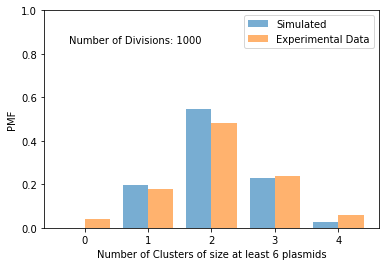

0 cluster: 0.0
1 cluster: 0.197
2 cluster: 0.546
3 cluster: 0.231
4 cluster: 0.026


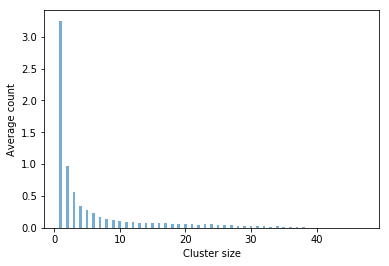

42.203


In [4]:
c_thresh = 6
cluster = True
gen=1000
x,t,ratio,c_num,z=single_lineage(x0,gen,tau,cluster,c_thresh,beta,gamma,sigma)
heights = np.bincount(c_num.astype(int))/len(c_num)
f = plt.figure()
bars = plt.bar(np.arange(len(heights))-0.2,heights,width=0.4,color='C0',alpha=0.6,label='Simulated') 
plt.text(-0.25,0.85,'Number of Divisions: %d' %len(c_num))
plt.bar(np.arange(5)+0.2,[0.04,0.18,0.48,0.24,0.06],width=0.4,color='C1',alpha=0.6,label='Experimental Data')
plt.ylim([0,1])
plt.xticks(range(len(heights)))
plt.xlabel('Number of Clusters of size at least %d plasmids' %(c_thresh))
plt.ylabel('PMF')
plt.legend()
plt.show()
for i in range(len(heights)):
    print('%d cluster:' %(i),heights[i])
    

f = plt.figure()
last = np.max(np.where(z>0)[0])
z[1]=z[0]
bars = plt.bar(np.arange(1,last+1),z[1:last+1]/len(c_num),width=0.4,color='C0',alpha=0.6) 
plt.xlabel('Cluster size')
plt.ylabel('Average count')
plt.show()
print(np.dot(np.arange(1,last+1),(z[1:last+1]/len(c_num))))

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:2: RuntimeWarning: divide by zero encountered in log
  


Text(0.5, 0, 'cluster size')

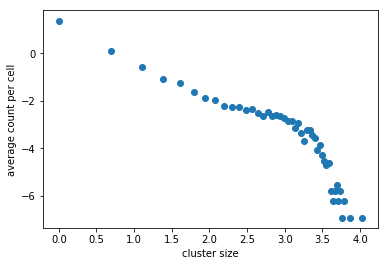

In [15]:
zz = z[1:last+1]/len(c_num)
plt.scatter(np.log(np.arange(1,last+1)),np.log(z[1:last+1]/len(c_num)))
plt.ylabel('average count per cell')
plt.xlabel('cluster size')

In [ ]:
zz

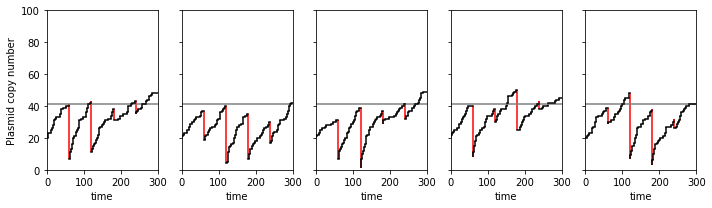

In [6]:
repeats = 5
gen=5
cluster=True
f,axes = plt.subplots(1,repeats,figsize=(10,3))
for i in range(repeats):
    x,t,_,__,___=single_lineage(x0,gen,tau,cluster,0,beta,gamma,sigma)
    plot_stairs_multiple(x,t,i)
axes[0].set_ylabel('Plasmid copy number')    
plt.tight_layout()

In [ ]:
cluster=[False,True]
gen=100
f = plt.figure()
for j in range(2):
    x,t,ratio1,_=single_lineage(x0,gen,tau,cluster[j],0)
    ratio2 = np.zeros([len(ratio1),2])
    for i in range(len(ratio1)):
        ratio2[i,:]=[ratio1[i,0],1-ratio1[i,1]] 
    ratio = np.append(ratio1,ratio2,axis=0)
    sns.jointplot(ratio[:,0],ratio[:,1])
    if cluster[j]==True:
        ratio_c = ratio
    else:
        ratio_uc = ratio

In [ ]:
f,axes=plt.subplots(2,1)
sns.kdeplot(ratio_uc[:,1],label='Binomial',shade=True,ax=axes[0],color='r')
sns.kdeplot(ratio_c[:,1],label='Clustered',shade=True,ax=axes[0],color='C0')
axes[0].set_xlabel(r'$N_d/N_p$',fontsize=14)
axes[0].text(-0.1,4,'Number of Divisions: %d' %(int(len(ratio_c)/2)), color='C0')
axes[0].set_ylim([0,5])

sns.kdeplot(ratio_uc[:,0],label='Binomial',shade=True,ax=axes[1],color='r')
sns.kdeplot(ratio_c[:,0],label='Clustered',shade=True,ax=axes[1],color='C0')
axes[1].set_xlabel(r'$N_p$',fontsize=14)
plt.tight_layout()

In [ ]:
beta_v  = np.array([0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1])
gamma_v = np.array([0.1,0.2,0.3,0.1,0.1,0.2,0.3,0.2,0.3,0.05,0.025,0.075,0.025,0.075])
sigma_v = np.array([0.1,0.2,0.3,0.2,0.3,0.1,0.1,0.3,0.2,0.05,0.025,0.075,0.075,0.025])
c1 = np.array([0.27,0.22,0.232,0.27,0.25,0.22,0.26,0.27,0.18,0.22,0.29,0.25,0.24,0.23])
c2 = np.array([0.47,0.58,0.49,0.47,0.49,0.52,0.51,0.43,0.59,0.5,0.46,0.48,0.5,0.49])
c3 = np.array([0.23,0.18,0.234,0.25,0.25,0.23,0.21,0.27,0.22,0.26,0.24,0.24,0.23,0.26])

plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c3,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 3 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()


plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c2,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 2 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()

plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c1,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 1 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()

In [ ]:
beta_v = np.array([0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001])
gamma_v = np.array([0.001,0.002,0.003,0.001,0.003,0.001,0.002,0.002,0.003,0.0005,0.00025,0.00075,0.00025,0.00025,0.0005,0.0005,0.00075,0.00075])
sigma_v = np.array([0.001,0.002,0.003,0.003,0.001,0.002,0.003,0.001,0.002,0.0005,0.00025,0.00075,0.0005,0.00075,0.00075,0.00025,0.00025,0.0005])
c0 = np.array([0.296,0.313,0.299,0.302,0.288,0.309,0.0301,0.272,0.308,0.312,0.276,0.288,0.284,0.309,0.297,0.302,0.296,0.306])
c1 = np.array([0.464,0.467,0.45,0.452,0.454,0.467,0.464,0.482,0.478,0.456,0.496,0.45,0.463,0.448,0.459,0.469,0.486,0.47])
c2 = np.array([0.205,0.184,0.21,0.218,0.216,0.191,0.21,0.21,0.175,0.196,0.198,0.219,0.216,0.21,0.212,0.207,0.186,0.201])
c3 = np.array([0.034,0.036,0.039,0.027,0.041,0.31,0.024,0.033,0.038,0.035,0.028,0.042,0.036,0.029,0.03,0.21,0.032,0.022])

plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c3,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 3 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()

plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c2,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 2 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()

plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c1,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 1 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()

plt.scatter(gamma_v/beta_v,sigma_v/beta_v,c=c0,cmap='viridis',s=80)
plt.clim(0,0.6)
plt.colorbar()
plt.title('Probability of having 0 clusters before division')
plt.xlabel(r'$\gamma/\beta$')
plt.ylabel(r'$\sigma/\beta$')
plt.show()

